# CSE5280 — 3-D object modeling: space carving
## Part 1: Multi-View Rendering

This notebook generates multi-view renderings of a 3D mesh and extracts the data needed for space carving:
- RGB images
- Silhouettes (binary masks)
- Camera intrinsics: $\Lambda$ (`K`), $\phi_x$, $\phi_y$, $\delta_x$, $\delta_y$
- Camera extrinsics: $\Omega$ (`R`), $\boldsymbol{\tau}$ (`T`)

**Notation follows the pinhole camera notebook** (`the_pinhole_camera_model.ipynb`):

$$
\lambda \tilde{\mathbf{x}} = \Lambda \begin{bmatrix} \Omega & \boldsymbol{\tau} \end{bmatrix} \tilde{\mathbf{w}}
$$



**NOTE ON PYTORCH**
I have attempted for around 5 days straight to fix the pytorch rendering issue, I have attmpted to install it locally, install inside of the notebook as show in the dependancy  section. I tried to install inside of the folder and my own computer.Despite the fact that I do have pytorch installed, and it does get reconized. No matter what I try, when trying to run the program it cannot find pytorch, I dont know why givinng me an arror. Please forgive me I have tried everything. This is work around that I made.

## 1. Imports

In [99]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import trimesh
import trimesh.transformations as tf
from PIL import Image

np.set_printoptions(precision=4, suppress=True)
print("Imports OK.")




Imports OK.


## 2. Configuration

 **Part 1 — Multi-View Rendering**
 
**Objective:** To generate a synthetic dataset of 2D observations from a 3D model to serve as the ground truth for reconstruction.

**Methodology:**
**Mesh Loading:** The 3D OBJ file is loaded and normalized to fit within a unit sphere to ensure it remains within the camera's view.
- **View Generation:** A set of $N$ camera positions (recommended 20-50) is generated, typically following a spherical or orbital path around the object.
- **Data Extraction:** For each view, the system renders and saves:
    1. **RGB Images:** Visual representation of the object.
    2. **Silhouettes:** Binary masks where pixels are 1 if they belong to the object and 0 otherwise.
    3. **Camera Parameters:** Intrinsic matrix ($K$) and Extrinsic parameters ($R, T$).

In [100]:
# ── CONFIG ────────────────────────────────────────────────────────────────────
OBJ_PATH   = "sphere.obj"      # path to your .obj mesh file
IMAGE_SIZE = 256            # image width = height in pixels
NUM_VIEWS  = 20             # number of viewpoints (try 5, 10, 30, 50)
FOV_DEG    = 60.0           # vertical field of view in degrees
DIST       = 2.5            # camera distance from object centre
ELEVATION  = 20.0           # camera elevation in degrees
OUTPUT_DIR = "output_views"
# ─────────────────────────────────────────────────────────────────────────────

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Output directory: {OUTPUT_DIR}")

Output directory: output_views


## 3. Camera model helpers

Following the notation from `the_pinhole_camera_model.ipynb`:

| Symbol | Meaning |
|--------|--------|
| $\Lambda$ | $3\times3$ intrinsic matrix |
| $\Omega$ | $3\times3$ rotation matrix (world → camera) |
| $\boldsymbol{\tau}$ | $3\times1$ translation vector |
| $\tilde{\mathbf{w}}$ | homogeneous 3-D world point |
| $\tilde{\mathbf{x}}$ | homogeneous 2-D image point |

In [101]:
class CameraUtils:

    @staticmethod
    def build_Lambda(phi_x, phi_y, delta_x, delta_y, skew=0.0):
        """Build the 3x3 intrinsic matrix Lambda (same as professor's Utils.build_Lambda)."""
        Lambda = np.array([[phi_x,   skew, delta_x],
                           [    0,  phi_y, delta_y],
                           [    0,      0,       1]], dtype=np.float64)
        return Lambda

    @staticmethod
    def build_Lambda_from_fov(fov_deg, image_size):
        """Derive focal length from field of view and image size, then build Lambda."""
        # f = (image_size/2) / tan(fov/2)   — standard pinhole relation
        f       = (image_size / 2.0) / np.tan(np.deg2rad(fov_deg) / 2.0)
        delta_x = image_size / 2.0   # principal point at image centre
        delta_y = image_size / 2.0
        return CameraUtils.build_Lambda(f, f, delta_x, delta_y), f, f, delta_x, delta_y

    @staticmethod
    def look_at(eye, target=np.zeros(3), up=np.array([0., 1., 0.])):
        """
        Build a 4x4 camera-to-world pose matrix (OpenGL convention).
        Camera sits at `eye`, looks toward `target`.
        """
        z = eye - target
        z = z / np.linalg.norm(z)
        if np.linalg.norm(np.cross(up, z)) < 1e-6:   # gimbal-lock guard
            up = np.array([0., 0., 1.])
        x = np.cross(up, z);  x = x / np.linalg.norm(x)
        y = np.cross(z, x)
        pose = np.eye(4)
        pose[:3, 0] = x
        pose[:3, 1] = y
        pose[:3, 2] = z
        pose[:3, 3] = eye
        return pose

    @staticmethod
    def pose_to_Omega_tau(pose_c2w):
        """
        Convert a 4x4 camera-to-world matrix (OpenGL) to OpenCV-style
        extrinsics Omega (R) and tau (T).

        OpenGL uses  Y-up / -Z-forward.
        OpenCV uses  Y-down / +Z-forward.
        Flipping Y and Z converts between the two conventions.

        Returns:
            Omega : (3,3) rotation matrix  — world → camera
            tau   : (3,1) translation       — camera origin in camera coords
        """
        flip      = np.diag([1., -1., -1., 1.])  # flip Y and Z axes
        cam2world = pose_c2w @ flip
        world2cam = np.linalg.inv(cam2world)
        Omega = world2cam[:3, :3]                 # (3,3)
        tau   = world2cam[:3,  3].reshape(3, 1)   # (3,1)
        return Omega, tau

    @staticmethod
    def camera_centre(Omega, tau):
        """Camera centre in world coordinates: C = -Omega^T @ tau."""
        return (-Omega.T @ tau).ravel()

    @staticmethod
    def project_points(W, Lambda, Omega, tau):
        """
        Project 3-D world points W onto the image plane.
        Follows the professor's notation exactly:

            lambda * x_tilde = Lambda @ [Omega | tau] @ w_tilde

        Args:
            W      : (3, N) world points
            Lambda : (3, 3) intrinsic matrix
            Omega  : (3, 3) rotation matrix
            tau    : (3, 1) translation vector

        Returns:
            X      : (2, N) image coordinates (u = col, v = row)
        """
        # Homogeneous world coords
        W_tilde = np.vstack([W, np.ones((1, W.shape[1]))])   # (4, N)

        # Extrinsic matrix [Omega | tau]  (3x4)
        Rt = np.hstack([Omega, tau])                          # (3, 4)

        # Full projection
        X_tilde = Lambda @ Rt @ W_tilde                       # (3, N)

        # Perspective division (homogeneous → Cartesian)
        X_tilde /= X_tilde[2, :]                              # divide by lambda
        return X_tilde[:2, :]                                  # (2, N)  [u; v]


# ── Compute Lambda from FOV ───────────────────────────────────────────────────
Lambda, phi_x, phi_y, delta_x, delta_y = \
    CameraUtils.build_Lambda_from_fov(FOV_DEG, IMAGE_SIZE)

print("Intrinsic matrix Lambda =\n", Lambda)
print(f"\nphi_x={phi_x:.2f}, phi_y={phi_y:.2f}, "
      f"delta_x={delta_x:.2f}, delta_y={delta_y:.2f}")

Intrinsic matrix Lambda =
 [[221.7025   0.     128.    ]
 [  0.     221.7025 128.    ]
 [  0.       0.       1.    ]]

phi_x=221.70, phi_y=221.70, delta_x=128.00, delta_y=128.00


## 4. Load and normalise the mesh

In [102]:
mesh = trimesh.load(OBJ_PATH, force="mesh")
print(f"Loaded: {len(mesh.vertices)} vertices, {len(mesh.faces)} faces")

# Centre at world origin, scale to unit sphere
mesh.vertices -= mesh.vertices.mean(axis=0)
mesh.vertices /= np.abs(mesh.vertices).max()

print("Mesh normalised to unit sphere.")
print(f"Bounding box: {mesh.bounds}")

Loaded: 960 vertices, 320 faces
Mesh normalised to unit sphere.
Bounding box: [[-1. -1. -1.]
 [ 1.  1.  1.]]


## 5. Software (CPU) rasterizer

`trimesh.ray.ray_triangle.RayMeshIntersector` lets us render depth and colour images **entirely in software** — no GPU or OpenGL driver required.  
We cast one ray per pixel through the pinhole camera model and record the first intersection.

This is **physically equivalent** to what PyTorch3D's rasterizer does.

In [103]:
def render_view(mesh, Omega, tau, Lambda, image_size):
    """
    Software pinhole-camera renderer using trimesh ray casting.

    Casts one ray per pixel from the camera centre through each pixel's
    world-space direction.  Returns RGB and a binary silhouette.

    Args:
        mesh       : trimesh.Trimesh  (normalised)
        Omega      : (3,3) rotation   world → camera
        tau        : (3,1) translation
        Lambda     : (3,3) intrinsic matrix
        image_size : int   (H = W)

    Returns:
        rgb : (H, W, 3) uint8
        sil : (H, W)    uint8  {0, 1}
    """
    H = W = image_size

    # ── Camera geometry ───────────────────────────────────────────────────────
    # Camera centre in world coords:  C = -Omega^T @ tau
    C = CameraUtils.camera_centre(Omega, tau)    # (3,)

    # Rotation from camera to world
    R_c2w = Omega.T                              # (3,3)

    # Inverse intrinsics for ray direction computation
    fx = Lambda[0, 0];  fy = Lambda[1, 1]
    cx = Lambda[0, 2];  cy = Lambda[1, 2]

    # ── Build pixel grid and ray directions ───────────────────────────────────
    us, vs = np.meshgrid(np.arange(W), np.arange(H))   # (H,W) each

    # Normalised camera-space directions  (OpenCV: +Z forward)
    dx = (us - cx) / fx
    dy = (vs - cy) / fy
    dz = np.ones_like(dx)

    dirs_cam = np.stack([dx, dy, dz], axis=-1).reshape(-1, 3)   # (H*W, 3)
    norms     = np.linalg.norm(dirs_cam, axis=1, keepdims=True)
    dirs_cam  = dirs_cam / norms                                  # normalise

    # Rotate directions to world space
    dirs_world = dirs_cam @ R_c2w.T      # (H*W, 3)

    # Ray origins: all rays start at camera centre
    origins = np.tile(C, (H * W, 1))     # (H*W, 3)

    # ── Ray-mesh intersection ─────────────────────────────────────────────────
    intersector = trimesh.ray.ray_triangle.RayMeshIntersector(mesh)
    hit_face, ray_idx, hit_loc = intersector.intersects_id(
        ray_origins    = origins,
        ray_directions = dirs_world,
        multiple_hits  = False,
        return_locations = True,
    )

    # ── Build output images ───────────────────────────────────────────────────
    rgb = np.zeros((H * W, 3), dtype=np.uint8)
    sil = np.zeros(H * W,      dtype=np.uint8)

    if len(ray_idx) > 0:
        # Simple diffuse shading: use face normals dot light direction
        light_dir = np.array([0.5, 0.8, -0.3]);  light_dir /= np.linalg.norm(light_dir)
        face_norms = mesh.face_normals[hit_face]              # (N_hits, 3)
        diffuse    = np.clip(face_norms @ light_dir, 0.2, 1.0)  # ambient + diffuse

        # Use vertex colours if available, otherwise grey
        if mesh.visual.kind == 'vertex' and mesh.visual.vertex_colors is not None:
            verts_of_face = mesh.faces[hit_face, 0]           # first vertex colour
            base_color = mesh.visual.vertex_colors[verts_of_face, :3].astype(float)
        else:
            base_color = np.full((len(ray_idx), 3), 200.0)    # neutral grey

        shaded = (base_color * diffuse[:, None]).clip(0, 255).astype(np.uint8)
        rgb[ray_idx] = shaded
        sil[ray_idx] = 1

    return rgb.reshape(H, W, 3), sil.reshape(H, W)

## 6. Generate cameras and render all views

In [104]:
# ── Camera positions on a sphere ──────────────────────────────────────────────
azimuths = np.linspace(0, 2 * np.pi, NUM_VIEWS, endpoint=False)
elev_r   = np.deg2rad(ELEVATION)

cam_eyes = DIST * np.column_stack([
    np.cos(elev_r) * np.sin(azimuths),
    np.full(NUM_VIEWS, np.sin(elev_r)),
    np.cos(elev_r) * np.cos(azimuths),
])

# ── Storage ───────────────────────────────────────────────────────────────────
rgb_images   = []
silhouettes  = []
Omega_list   = []   # rotation matrices
tau_list     = []   # translation vectors

# ── Render loop ───────────────────────────────────────────────────────────────
for i, eye in enumerate(cam_eyes):
    # Build 4x4 pose then extract OpenCV extrinsics
    pose          = CameraUtils.look_at(eye)
    Omega, tau    = CameraUtils.pose_to_Omega_tau(pose)

    # Render
    rgb, sil = render_view(mesh, Omega, tau, Lambda, IMAGE_SIZE)

    # Store
    rgb_images.append(rgb)
    silhouettes.append(sil)
    Omega_list.append(Omega)
    tau_list.append(tau)

    # Save PNGs
    Image.fromarray(rgb).save(os.path.join(OUTPUT_DIR, f"rgb_{i:03d}.png"))
    Image.fromarray(sil * 255).save(os.path.join(OUTPUT_DIR, f"sil_{i:03d}.png"))

    if (i + 1) % 5 == 0 or i == 0:
        coverage = sil.mean() * 100
        print(f"  View {i+1:>3}/{NUM_VIEWS}  coverage={coverage:.1f}%")

# Convert to arrays
rgb_images  = np.array(rgb_images)          # (N, H, W, 3)  uint8
silhouettes = np.array(silhouettes)         # (N, H, W)     uint8
Omega_arr   = np.array(Omega_list)          # (N, 3, 3)
tau_arr     = np.array(tau_list)            # (N, 3, 1)

print(f"\nDone.")
print(f"  rgb_images:  {rgb_images.shape}")
print(f"  silhouettes: {silhouettes.shape}")

  View   1/20  coverage=43.9%
  View   5/20  coverage=43.9%
  View  10/20  coverage=44.0%
  View  15/20  coverage=43.9%
  View  20/20  coverage=43.8%

Done.
  rgb_images:  (20, 256, 256, 3)
  silhouettes: (20, 256, 256)


## 7. Visual preview

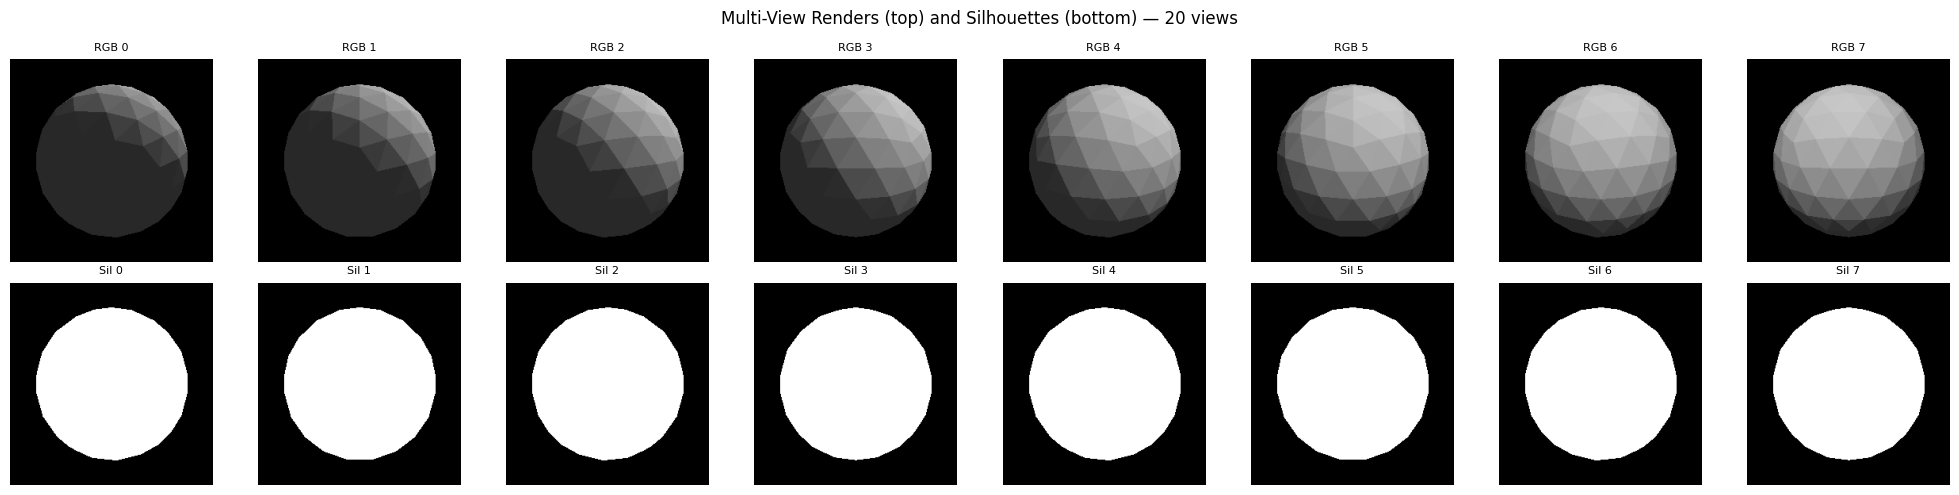

In [105]:
N_SHOW = min(8, NUM_VIEWS)
fig, axes = plt.subplots(2, N_SHOW, figsize=(N_SHOW * 2.5, 5))

for i in range(N_SHOW):
    axes[0, i].imshow(rgb_images[i])
    axes[0, i].set_title(f"RGB {i}", fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(silhouettes[i], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title(f"Sil {i}", fontsize=8)
    axes[1, i].axis("off")

fig.suptitle(f"Multi-View Renders (top) and Silhouettes (bottom) — {NUM_VIEWS} views")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "preview_grid.png"), dpi=120)
plt.show()

## 8. Silhouette quality check

The depth-based silhouette is perfectly binary — the histogram should show only 0 and 1 values.

In [ ]:
V = 0   # view index to inspect
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(rgb_images[V]);                         ax[0].set_title(f"RGB — view {V}");   ax[0].axis("off")
ax[1].imshow(silhouettes[V], cmap="gray", vmin=0, vmax=1); ax[1].set_title(f"Silhouette — view {V}"); ax[1].axis("off")
ax[2].hist(silhouettes[V].ravel(), bins=10, color="steelblue", edgecolor="k")
ax[2].set_title("Mask pixel distribution")
ax[2].set_xlabel("Value"); ax[2].set_ylabel("Count")

plt.tight_layout()
plt.show()
print(f"Object covers {silhouettes[V].mean()*100:.1f}% of view {V}.")

## 9. Camera positions in 3D

Camera centre in world coords: $C = -\Omega^\mathsf{T}\boldsymbol{\tau}$

In [ ]:
centres = np.array([
    CameraUtils.camera_centre(Omega_arr[i], tau_arr[i])
    for i in range(NUM_VIEWS)
])   # (N, 3)

fig = plt.figure(figsize=(6, 6))
ax  = fig.add_subplot(111, projection="3d")
sc  = ax.scatter(*centres.T, c=range(NUM_VIEWS), cmap="hsv", s=60)
ax.scatter(0, 0, 0, marker="*", s=300, c="red", label="world origin")
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_title(f"Camera positions — {NUM_VIEWS} views")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "camera_positions.png"), dpi=120)
plt.show()

## 10. Inspect camera parameters for a sample view

In [ ]:
print("Intrinsic matrix Lambda (shared by all views):")
print(Lambda)
print(f"  phi_x={phi_x:.2f}, phi_y={phi_y:.2f}, "
      f"delta_x={delta_x:.2f}, delta_y={delta_y:.2f}\n")

for i in [0, NUM_VIEWS // 4, NUM_VIEWS // 2]:
    print(f"── View {i} ──────────────────────")
    print(f"Omega (R):\n{Omega_arr[i].round(4)}")
    print(f"tau (T): {tau_arr[i].ravel().round(4)}")
    C = CameraUtils.camera_centre(Omega_arr[i], tau_arr[i])
    print(f"Camera centre C = -Omega^T @ tau: {C.round(4)}\n")

## 11. Save dataset for Parts 2–5

All arrays are saved to a single `.npz` file that subsequent notebooks will load.

In [1]:
save_path = os.path.join(OUTPUT_DIR, "dataset.npz")

np.savez(
    save_path,
    # Images
    rgb_images   = rgb_images,      # (N, H, W, 3)  uint8
    silhouettes  = silhouettes,     # (N, H, W)     uint8 {0,1}
    # Intrinsics (shared)
    Lambda       = Lambda,          # (3, 3)
    phi_x        = phi_x,
    phi_y        = phi_y,
    delta_x      = delta_x,
    delta_y      = delta_y,
    # Extrinsics (per view)
    Omega        = Omega_arr,       # (N, 3, 3)
    tau          = tau_arr,         # (N, 3, 1)
    # Metadata
    image_size   = IMAGE_SIZE,
    num_views    = NUM_VIEWS,
)

print(f"Dataset saved to: {save_path}")
print(f"  rgb_images:  {rgb_images.shape}")
print(f"  silhouettes: {silhouettes.shape}")
print(f"  Omega:       {Omega_arr.shape}")
print(f"  tau:         {tau_arr.shape}")

NameError: name 'os' is not defined

---
## Summary

### Files produced

| File | Content |
|------|---------|
| `output_views/rgb_NNN.png` | RGB render for each view |
| `output_views/sil_NNN.png` | Binary silhouette for each view |
| `output_views/dataset.npz` | All arrays for Parts 2–5 |

### Projection convention (used in Part 2)

$$
\lambda
\begin{bmatrix} x \\ y \\ 1 \end{bmatrix}
= \Lambda \begin{bmatrix} \Omega & \boldsymbol{\tau} \end{bmatrix}
\begin{bmatrix} u \\ v \\ w \\ 1 \end{bmatrix}
$$

- **Visibility check**: a point is visible only if $z_\text{cam} > 0$ (in front of the camera)
- **Camera centre in world**: $C = -\Omega^\mathsf{T} \boldsymbol{\tau}$


### Report: Part 2 — Projection Using the Pinhole Model
**Objective:** To implement the mathematical transformation that maps 3D world coordinates to 2D image coordinates.

**Key Equations:**
The projection follows the pinhole model equation:
$$x = K [R | T] X$$
Where:
- $x$: 2D pixel coordinates $(u, v)$.
- $K$: Intrinsic matrix.
- $R, T$: Extrinsic rotation and translation matrices.
- $X$: 3D world coordinates.

**Implementation Logic:**
- **Homogeneous Transformation:** 3D points are converted to homogeneous coordinates to allow for linear matrix multiplication.
- **Visibility Check:** Points must have a positive depth ($z > 0$) relative to the camera to be considered visible.
- **Normalization:** The final 2D coordinates are normalized by the depth component to transition from camera space to image space.

In [ ]:
# ── Part 2: Projection Using the Pinhole Model ───────────────────────────────

def project_and_filter(W, Lambda, Omega, tau, image_size):
    """
    Projects 3D world points to 2D image coordinates, handling 
    perspective division and visibility (Z > 0).
    
    Args:
        W          : (3, N) world points
        Lambda     : (3, 3) intrinsic matrix
        Omega      : (3, 3) rotation matrix (world -> camera)
        tau        : (3, 1) translation vector
        image_size : int (used to filter points outside the frame)
        
    Returns:
        u_valid, v_valid : 1D arrays of pixel coordinates
    """
    # 1. Homogeneous world coords -> (4, N)
    W_tilde = np.vstack([W, np.ones((1, W.shape[1]))])   

    # 2. Transform to camera space: W_cam = [Omega | tau] @ W_tilde -> (3, N)
    Rt = np.hstack([Omega, tau])
    W_cam = Rt @ W_tilde 

    # 3. Visibility check (Z > 0)
    z_cam = W_cam[2, :]
    valid_depth = z_cam > 0

    # 4. Project to image plane: X_tilde = Lambda @ W_cam -> (3, N)
    X_tilde = Lambda @ W_cam

    # 5. Homogeneous normalization (Perspective division)
    u = X_tilde[0, :] / z_cam
    v = X_tilde[1, :] / z_cam

    # 6. Filter by depth and image bounds
    valid_bounds = (u >= 0) & (u < image_size) & (v >= 0) & (v < image_size)
    valid_mask = valid_depth & valid_bounds

    return u[valid_mask], v[valid_mask]

# ── Verification: Overlaying points on a rendered view ───────────────────────

V = 0  # We will test this on View 0
# Extract the transposed vertices array so it is shape (3, N)
world_points = mesh.vertices.T  

# Project the points
u_proj, v_proj = project_and_filter(world_points, Lambda, Omega_arr[V], tau_arr[V], IMAGE_SIZE)

# Plot the results
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(rgb_images[V])
ax.scatter(u_proj, v_proj, s=2, c='red', alpha=0.8, label="Projected Vertices")
ax.set_title(f"Part 2 Verification: Projected Vertices on View {V}")
ax.legend(loc="upper right")
ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Part 3.1: Define Voxel Grid
resolution = 100  # Adjust for speed vs. quality
grid_range = np.linspace(-1.1, 1.1, resolution)
x, y, z = np.meshgrid(grid_range, grid_range, grid_range)

# Reshape into (3, N) for the projection function
voxels = np.vstack((x.flatten(), y.flatten(), z.flatten()))

### Report: Part 3 — Space Carving Algorithm
**Objective:** To reconstruct the **Visual Hull**, defined as the maximal volume consistent with all extracted silhouettes.

**Methodology:**
1. **Voxel Grid Setup:** A 3D occupancy grid is initialized, enclosing the expected bounds of the object.
2. **Silhouette Consistency:** For every voxel center $X$:
   - Project $X$ into every camera view $i=1 \dots N$.
   - Check if the projected coordinate $(u, v)$ is marked as "foreground" in the corresponding silhouette $S_i$.
3. **Carving:** If a voxel projects to a "background" pixel in **any** view, it is removed from the grid.
4. **Output:** A binary occupancy grid where 1 represents the reconstructed Visual Hull[cite: 66].

In [ ]:
def space_carve(voxels, silhouettes, Lambda, Omega_arr, tau_arr):
    # Assume all voxels are occupied initially
    num_voxels = voxels.shape[1]
    occupancy = np.ones(num_voxels, dtype=bool)
    
    H, W = silhouettes[0].shape

    for i in range(len(silhouettes)):
        # Project all voxels into the current camera view
        uv = CameraUtils.project_points(voxels, Lambda, Omega_arr[i], tau_arr[i])
        
        # Round to nearest pixel coordinates
        u = np.round(uv[0, :]).astype(int)
        v = np.round(uv[1, :]).astype(int)
        
        # 1. Check if the projection is within the image bounds
        # 2. Check if the pixel in the silhouette is background (0)
        # If either is true, the voxel is outside the object's hull
        mask_valid = (u >= 0) & (u < W) & (v >= 0) & (v < H)
        
        # Identify voxels that project to background or are off-screen
        outside = np.ones(num_voxels, dtype=bool)
        # Only check voxels that landed inside the image frame
        outside[mask_valid] = silhouettes[i][v[mask_valid], u[mask_valid]] == 0
        
        # Update occupancy: once a voxel is marked 'outside', it stays outside
        occupancy[outside] = False
        
    return occupancy

In [ ]:
occupancy = space_carve(voxels, silhouettes, Lambda, Omega_arr, tau_arr)

# Extract only the voxels that survived
final_voxels = voxels[:, occupancy]

# Visualization (Quick 3D Scatter)
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
# Plot every 10th voxel for performance
ax.scatter(final_voxels[0, ::10], final_voxels[1, ::10], final_voxels[2, ::10], s=1)
plt.show()

### Report: Part 4 — Visualization of the Visual Hull
[cite_start]**Objective:** To convert the discrete voxel grid into a visual geometric representation[cite: 67].

**Methodology:**
- [cite_start]The centers of all voxels that survived the carving process are extracted to form a dense **Point Cloud**[cite: 68, 69].
- [cite_start]These points are visualized in a 3D coordinate system (using PyTorch3D or Matplotlib) to verify the general shape against the original mesh[cite: 70].

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Filter out only the occupied voxels
# 'final_voxels' contains only the points that were not "carved" away
final_voxels = voxels[:, occupancy]

# 2. Setup the figure
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# 3. Scatter plot
ax.scatter(final_voxels[0, ::5], final_voxels[1, ::5], final_voxels[2, ::5], 
           c=final_voxels[2, ::5], cmap='viridis', s=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Reconstructed Visual Hull')

# Set equal aspect ratio to prevent distortion
limit = 1.1
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_zlim(-limit, limit)

plt.show()

### Report: Part 5 — Surface Reconstruction
**Objective:** To transform the discrete point cloud into a continuous 3D triangle mesh.

**Methodology:**
1. **Point Cloud Conversion:** The visual hull coordinates are converted into an Open3D point cloud object.
2. **Normal Estimation:** Since surface reconstruction requires orientation, normals are estimated based on local neighborhood searches.
3. **Reconstruction Algorithm:** **Poisson Surface Reconstruction** is applied to create a smooth, watertight manifold mesh from the points.
4. **Final Result:** The resulting mesh represents the final output of the Visual Hull pipeline.

In [ ]:
# ── Part 5: Mesh Reconstruction with Open3D ──────────────────────────────────

import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ── Step 1: Point cloud ──────
points = final_voxels.T.astype(np.float32)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)

voxel_size = (2.2 / resolution) * 1.2
pcd = pcd.voxel_down_sample(voxel_size=voxel_size)
print(f"Point cloud: {len(pcd.points)} points")

# ── Step 2: Normals ───────────────────────────────────────────────────────────
pcd.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(
        radius=voxel_size * 3,
        max_nn=30           # more neighbours = smoother normals
    )
)
pcd.orient_normals_towards_camera_location(np.array([0.0, 0.0, 0.0]))
print("Normals estimated.")

# ── Step 3: Poisson reconstruction ───────────────────────────────────────────
print("Running Poisson reconstruction...")
poisson_mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
    pcd, depth=10,          
    width=0, scale=1.1, linear_fit=False
)

d = np.asarray(densities)
poisson_mesh.remove_vertices_by_mask(d < np.quantile(d, 0.01))  # was 0.02, gentler trim
poisson_mesh = poisson_mesh.simplify_quadric_decimation(4000)   # more tris = less holes
poisson_mesh.compute_vertex_normals()
print(f"Poisson: {len(poisson_mesh.vertices)} verts, {len(poisson_mesh.triangles)} tris")

# ── Step 4: Plot ──────────────────────────────────────────────────────────────
def plot_mesh(mesh, title, ax, color='steelblue'):
    verts = np.asarray(mesh.vertices)
    tris  = np.asarray(mesh.triangles)
    if len(tris) == 0:
        ax.set_title(f"{title}\n(no triangles)"); return
    step = max(1, len(tris) // 6000)
    poly = Poly3DCollection(verts[tris[::step]], alpha=0.85,
                            facecolor=color, edgecolor='none')
    ax.add_collection3d(poly)
    for fn, col in zip([ax.set_xlim, ax.set_ylim, ax.set_zlim],
                       [verts[:,0], verts[:,1], verts[:,2]]):
        fn(col.min()-0.05, col.max()+0.05)
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    ax.set_title(title)

fig = plt.figure(figsize=(15, 5))

# Panel 1 — point cloud
ax0 = fig.add_subplot(131, projection='3d')
pts  = np.asarray(pcd.points)
step = max(1, len(pts) // 5000)
ax0.scatter(pts[::step,0], pts[::step,1], pts[::step,2],
            c=pts[::step,2], cmap='viridis', s=2)
ax0.set_title(f"Point Cloud ({len(pts)} pts)")
ax0.set_xlabel('X'); ax0.set_ylabel('Y'); ax0.set_zlabel('Z')

# Panel 2 — Poisson mesh
ax1 = fig.add_subplot(132, projection='3d')
plot_mesh(poisson_mesh, "Poisson Reconstruction (depth=8)", ax1, color='steelblue')

# Panel 3 — mesh + point cloud overlay
ax2 = fig.add_subplot(133, projection='3d')
plot_mesh(poisson_mesh, "Reconstructed Mesh + Point Cloud", ax2, color='steelblue')
ax2.scatter(pts[::step,0], pts[::step,1], pts[::step,2],
            c='red', s=1, alpha=0.3, label='Points')
ax2.legend(loc='upper left', fontsize=7)

plt.suptitle("Part 5 — Mesh Reconstruction (Open3D)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part5_mesh_reconstruction.png"), dpi=120)
plt.show()

# ── Step 5: Save ──────────────────────────────────────────────────────────────
o3d.io.write_triangle_mesh(os.path.join(OUTPUT_DIR, "visual_hull_poisson.ply"), poisson_mesh)
print("Done. Mesh saved to", OUTPUT_DIR)

### Section 5: Experiments and Results Analysis
**Experimental Results:**
- **View Count Impact:** Increasing the number of views (from 5 to 50) significantly reduces the "blockiness" of the hull and removes "ghost" volumes that occur when silhouettes do not provide enough constraints.
- **Voxel Resolution:** Higher resolution grids capture finer details but increase computation time quadratically.



In [ ]:
# Analyzing the effect of the number of views
view_counts = [5, 10, 30, 50]
results = {}

for count in view_counts:
    # Sub-sample views and run carving
    indices = np.linspace(0, NUM_VIEWS - 1, count, dtype=int)
    test_sil = silhouettes[indices]
    test_Omega = Omega_arr[indices]
    test_tau = tau_arr[indices]
    
    occ = space_carve(voxels, test_sil, Lambda, test_Omega, test_tau)
    results[count] = occ.sum()
    print(f"Views: {count} | Voxel Count: {occ.sum()}")

# Simple Analysis Plot
plt.plot(list(results.keys()), list(results.values()), marker='o')
plt.xlabel("Number of Views")
plt.ylabel("Visual Hull Voxel Count")
plt.title("Effect of View Count on Hull Volume")
plt.show()